# Business health and discount dependency

Reference: **Two_Analytics_Projects_Complete_Guide.docx, Steps 1.2.1–1.2.4**.

The verified SQL is saved in `sql/02_health.sql`; results are generated by `scripts/run_business_health.py`. This notebook reads the exports so it does not interrupt DBeaver. No causal effect is estimated here.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path.cwd()
if not (ROOT / 'exports/business_health/weekly_kpis.csv').exists():
    ROOT = ROOT / 'outputs/grocery-marketing-effectiveness'
DATA = ROOT / 'exports/business_health'
weekly = pd.read_csv(DATA / 'weekly_kpis.csv', parse_dates=['week_start'])
category = pd.read_csv(DATA / 'category_discount.csv')
summary = pd.read_csv(DATA / 'business_health_summary.csv')
checks = pd.read_csv(DATA / 'business_health_checks.csv')
assert len(weekly) == 52 and weekly['week'].min() == 2 and weekly['week'].max() == 53
assert len(category) == 122
assert checks['passed'].astype(str).str.lower().eq('true').all()
display(summary.T)

,0
annual_grocery_sales,4.185056e+06
annual_grocery_baskets,1.410630e+05
annual_grocery_households,2.467000e+03
annual_grocery_shelf_value,4.968887e+06
annual_grocery_discount_depth,1.577479e-01
partial_week_1_sales,1.010685e+04
comparable_week_sales,4.174949e+06
unclassified_product_sales,1.725700e+02


## Weekly KPIs

Grocery purchases in source weeks 2–53. Partial week 1 is excluded. Do not sum weekly household counts to estimate annual unique households.

,week,week_start,first_observed_purchase_date,households,baskets,sales,aov,visits_per_hh,discount_depth,retailer_funded_discount_usd,shelf_value_usd
0,2,2017-01-02,2017-01-02,1292,2676,87182.19,32.58,2.07,0.1492,15291.98,102474.17
1,3,2017-01-09,2017-01-09,1261,2588,77454.82,29.93,2.05,0.1556,14271.67,91726.49
2,4,2017-01-16,2017-01-16,1293,2738,76394.52,27.90,2.12,0.1695,15597.19,91991.71
3,5,2017-01-23,2017-01-23,1261,2588,72653.19,28.07,2.05,0.1653,14389.42,87042.61
4,6,2017-01-30,2017-01-30,1308,2851,90024.21,31.58,2.18,0.1460,15389.17,105413.38
5,7,2017-02-06,2017-02-06,1254,2644,83061.84,31.42,2.11,0.1414,13678.75,96740.59
6,8,2017-02-13,2017-02-13,1275,2656,74802.89,28.16,2.08,0.1518,13387.25,88190.14
7,9,2017-02-20,2017-02-20,1286,2683,78675.89,29.32,2.09,0.1561,14549.80,93225.69
8,10,2017-02-27,2017-02-27,1300,2685,83797.80,31.21,2.07,0.1560,15486.85,99284.65
9,11,2017-03-06,2017-03-06,1266,2696,77785.83,28.85,2.13,0.1617,15008.49,92794.32


,average_week
households,1302.519231
sales,80287.476731
aov,29.666346
visits_per_hh,2.076346
discount_depth,0.157710


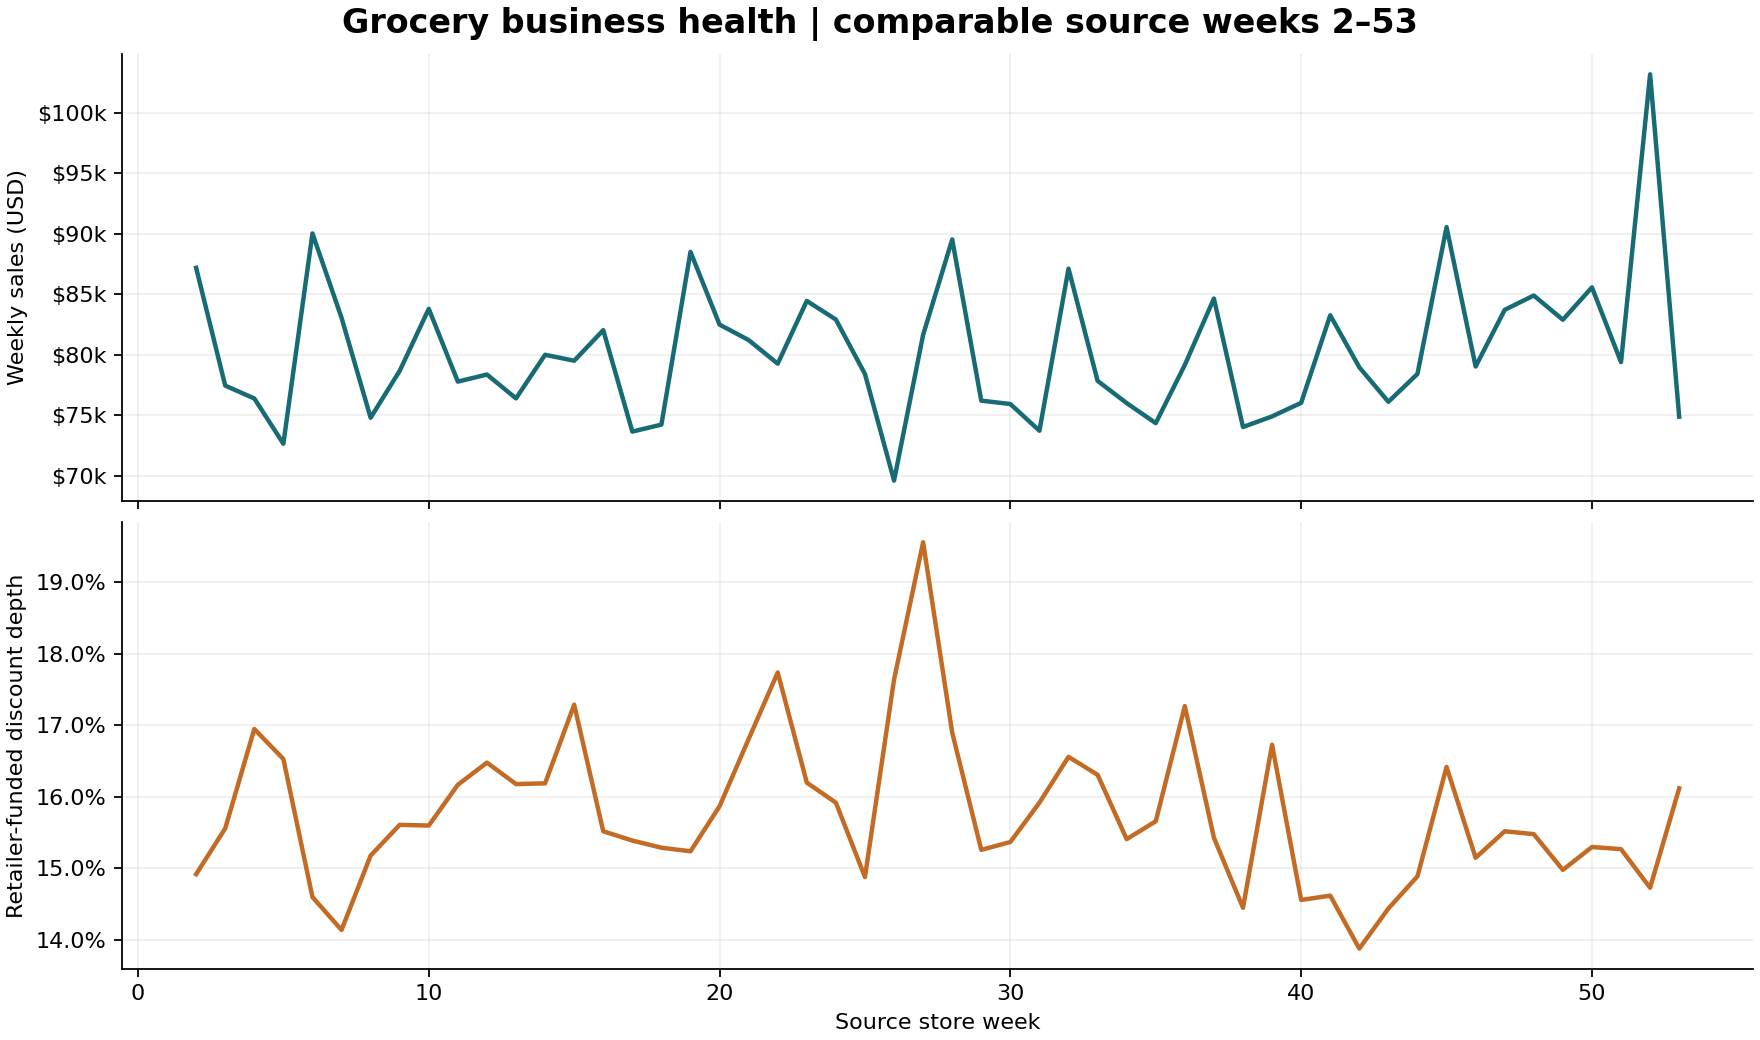

In [2]:
display(weekly.head(10))
display(weekly[['households', 'sales', 'aov', 'visits_per_hh', 'discount_depth']].mean().to_frame('average_week'))
display(Image(filename=str(ROOT / 'charts/weekly_health.png')))

## Discount dependency by category

Full-period categories with at least $10,000 sales. The discounted share is weighted by shelf value, not units. Categories with no retailer-funded discounts correctly have a zero share. This is an observed share, not a forecast of lost sales without discounts.

,department,product_category,sales,share_sold_on_discount,discount_depth,buyers
0,DRUG GM,INFANT FORMULA,26910.17,0.891799,0.126135,306
1,GROCERY,FRZN VEGETABLE/VEG DSH,25717.13,0.881773,0.191583,1491
2,GROCERY,FROZEN BREAD/DOUGH,10932.63,0.877926,0.162367,1219
3,MEAT-PCKGD,MEAT - MISC,37640.07,0.854599,0.238241,1311
4,GROCERY,ICE CREAM/MILK/SHERBTS,46876.51,0.854338,0.325930,1852
5,SEAFOOD-PCKGD,SEAFOOD - FROZEN,29007.72,0.814962,0.266744,1168
6,MEAT-PCKGD,FROZEN MEAT,29366.64,0.810170,0.166834,1220
7,GROCERY,FRZN MEAT/MEAT DINNERS,93023.74,0.809624,0.222776,1775


,department,product_category,sales,share_sold_on_discount,discount_depth,buyers
121,SPIRITS,LIQUOR,12299.52,0.000000,0.000000,395
120,DRUG GM,MAGAZINE,18220.96,0.000481,0.000096,927
119,DRUG GM,CIGARETTES,54349.68,0.002944,0.000240,768
118,GROCERY,DOMESTIC WINE,35927.70,0.004740,0.001108,535
117,GROCERY,BEERS/ALES,82026.66,0.007026,0.000864,1298
116,GROCERY,IMPORTED WINE,11365.68,0.015980,0.003821,277
115,DRUG GM,GREETING CARDS/WRAP/PARTY SPLY,19384.81,0.045072,0.029398,1312
114,FLORAL,FLORAL-FRESH CUT,11130.82,0.056778,0.021009,591


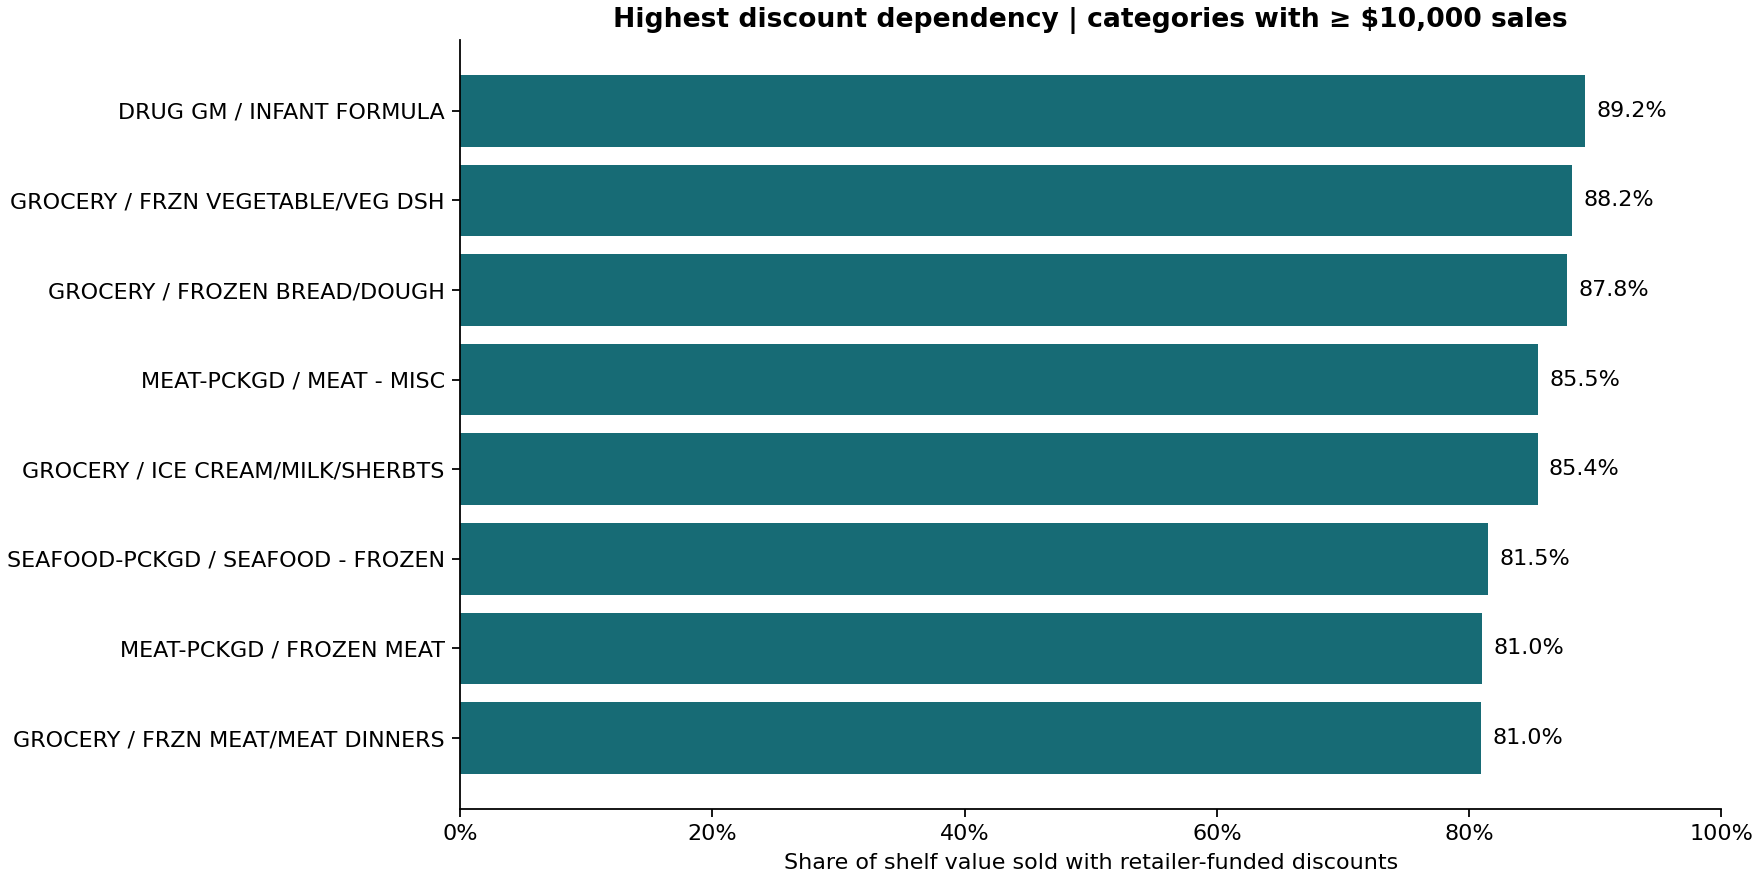

In [3]:
columns = ['department','product_category','sales','share_sold_on_discount','discount_depth','buyers']
display(category.sort_values('share_sold_on_discount', ascending=False)[columns].head(8))
display(category.sort_values('share_sold_on_discount')[columns].head(8))
display(Image(filename=str(ROOT / 'charts/category_discount_dependency.png')))

## Weekly association

This is an aggregate correlation. It does not control for seasonality, product mix, or campaign targeting and cannot establish a discount effect.

In [4]:
correlation = weekly['discount_depth'].corr(weekly['sales'])
print(f'Weekly discount-depth/sales correlation: {correlation:.4f}')
display(checks)
display(Markdown((ROOT / 'docs/business_health/findings.md').read_text(encoding='utf-8')))

Weekly discount-depth/sales correlation: -0.1252


,check_name,passed
0,52_comparable_weeks,True
1,weeks_2_to_53,True
2,weekly_sales_reconcile,True
3,weekly_baskets_reconcile,True
4,weekly_discount_amount_reconciles,True
5,weekly_shelf_value_reconciles,True
6,weekly_ratios_valid,True
7,category_ratios_valid,True
8,category_sales_floor,True
9,annual_sales_window_reconciles,True


# Business health

Completed Steps 1.2.1–1.2.4 using the verified grocery model. These are descriptive results, not estimates of what would happen if discounts were removed.

## Three findings

1. Comparable grocery weeks average **$80,287.48 sales**, **1,303 active households**, and **$29.67 average basket value**. Week 52 leads with **$103,168.27**; week 26 is lowest at **$69,610.66**. Use this baseline to investigate changes rather than compare partial week 1 against full weeks.
2. Average weekly retailer-funded discount depth is **15.77%**. Its correlation with weekly sales is **-0.125**. The weak weekly association does not establish whether discounts increase sales; promotion-level and campaign analyses are still needed.
3. **122 categories** meet the $10,000 sales floor. **INFANT FORMULA** has the highest shelf-value-weighted share sold on discount at **89.2%**. This identifies a category for closer margin and promotion analysis; it does not measure sales that would be lost without discounts.

## Scope and reconciliation

- Weekly trends use source weeks **2–53**, excluding partial week 1: **$4,174,948.79** sales over 52 weeks.
- Week labels are the actual Monday calendar starts. The first recorded purchase date is exported separately; week 53 starts 25 December even though its first observed purchase is 26 December.
- Annual/category analysis includes all source weeks: **$4,185,055.64** sales. Partial week 1 contributes **$10,106.85**, explaining the difference.
- The grocery filter excludes explicitly flagged non-grocery products. It still contains **$172.57** of UNKNOWN-product sales; their actual categories are unknown.
- Manufacturer coupon amounts are excluded from retailer-funded discount cost.
- Category discount share weights shelf value, not units or purchase lines. Categories below $10,000 are excluded only from the ranking.
- Ratios have exported base amounts so Power BI can recompute weighted totals. Do not sum weekly household counts to report annual distinct households or average category percentages without weighting.
- **11 business-health checks passed**, plus source fingerprint and clean-model reconciliation checks. No existing database was modified.

## Files to inspect

`exports/business_health/weekly_kpis.csv`, `category_discount.csv`, `business_health_summary.csv`, and `business_health_checks.csv`; `charts/weekly_health.png`; `charts/category_discount_dependency.png`; `02_business_health.ipynb`; and `sql/02_health.sql`.

The CSVs in `exports/business_health/` feed the Power BI report.


## Next guide section

Module 3 builds household metrics, segments, spend trajectories, and retention cohorts. The final Power BI dashboard is Step 1.7.3; these business-health exports are ready for a preview now.